In [2]:
from pathlib import Path

Path.cwd()
DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)
output_path = DATA_DIR / "era5_t2m_uk_summer_2020.nc"
print(output_path.resolve())

C:\WIP\my_work\climate-extremes\data\era5_t2m_uk_summer_2020.nc


In [5]:
import numpy as np
import pandas as pd
import xarray as xr
import cdsapi


In [ ]:

dataset = "reanalysis-era5-single-levels"
request = {
    "product_type": ["reanalysis"],
    "variable": ["2m_temperature"],
    "year": ["2020"],
    "month": ["06", "07", "08"],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "time": [
        "00:00", "01:00", "02:00",
        "03:00", "04:00", "05:00",
        "06:00", "07:00", "08:00",
        "09:00", "10:00", "11:00",
        "12:00", "13:00", "14:00",
        "15:00", "16:00", "17:00",
        "18:00", "19:00", "20:00",
        "21:00", "22:00", "23:00"
    ],
    "data_format": "netcdf",
    "download_format": "unarchived",
    "area": [60, -12, 48, 4]
}


client = cdsapi.Client()

client.retrieve(
    dataset,
    request,
    str(output_path)
)

2026-09-05 10:05:54,353 INFO Request ID is 5f6bb1dc-2402-4ec4-bb55-611ecb382013
2026-09-05 10:05:54,437 INFO status has been updated to accepted
2026-09-05 10:06:16,203 INFO status has been updated to running
2026-09-05 10:08:47,344 INFO status has been updated to successful


'..\\data\\era5_t2m_uk_summer_2020.nc'

In [ ]:
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("xarray:", xr.__version__)

NumPy: 2.5.1
pandas: 3.0.5
xarray: 2026.7.0


In [ ]:
print(output_path.exists())
print(f"{output_path.stat().st_size / 1024**2:.2f} MiB")

True
12.98 MiB


In [ ]:
ds = xr.open_dataset(output_path)
print(ds)

<xarray.Dataset> Size: 28MB
Dimensions:     (valid_time: 2208, latitude: 49, longitude: 65)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2020-06-01 ... 2020-08-31T23...
    expver      (valid_time) <U4 35kB ...
  * latitude    (latitude) float64 392B 60.0 59.75 59.5 ... 48.5 48.25 48.0
  * longitude   (longitude) float64 520B -12.0 -11.75 -11.5 ... 3.5 3.75 4.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 28MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-05T09:08 GRIB to CDM+CF via cfgrib-0.9.1...


In [ ]:
t2m = ds["t2m"]
print(t2m.shape)
print(t2m.dims)
print(t2m.dtype)
print(t2m.attrs)

(2208, 49, 65)
('valid_time', 'latitude', 'longitude')
float32
{'GRIB_paramId': np.int64(167), 'GRIB_dataType': 'an', 'GRIB_numberOfPoints': np.int64(3185), 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': np.int64(1), 'GRIB_stepType': 'instant', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': np.int64(0), 'GRIB_NV': np.int64(0), 'GRIB_Nx': np.int64(65), 'GRIB_Ny': np.int64(49), 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 't2m', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_iScansNegatively': np.int64(0), 'GRIB_jDirectionIncrementInDegrees': np.float64(0.25), 'GRIB_jPointsAreConsecutive': np.int64(0), 'GRIB_jScansPositively': np.int64(0), 'GRIB_latitudeOfFirstGridPointInDegrees': np.float64(60.0), 'GRIB_latitudeOfLastGridPointInDegrees': np.float64(48.0), 'GRIB_longitudeOfFirstGridPointInDegrees': np.float64(-12.0), 'GRIB_longitudeOfLastGridPointInDegrees': np.float64(4.0), 'GRIB_missingValue': np.float

In [ ]:
point = t2m.isel(latitude=20, longitude=30)
print(point.shape)
print(point.dims)
print(point.latitude.values)
print(point.longitude.values)
print(point)


(2208,)
('valid_time',)
55.0
-4.5
<xarray.DataArray 't2m' (valid_time: 2208)> Size: 9kB
[2208 values with dtype=float32]
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2020-06-01 ... 2020-08-31T23...
    expver      (valid_time) <U4 35kB ...
    number      int64 8B ...
    latitude    float64 8B 55.0
    longitude   float64 8B -4.5
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3185
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_s

In [ ]:
point_c = point - 273.15
#print(point_c)

point_c.attrs["units"] = "degC"
point_c.isel(valid_time=slice(0, 5))
print(point_c)

<xarray.DataArray 't2m' (valid_time: 2208)> Size: 9kB
array([12.659821, 12.057037, 11.649811, ..., 10.648102, 10.842438,
       10.547516], shape=(2208,), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2020-06-01 ... 2020-08-31T23...
    expver      (valid_time) <U4 35kB ...
    number      int64 8B ...
    latitude    float64 8B 55.0
    longitude   float64 8B -4.5
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3185
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard

In [ ]:
#print(point_c.isel(valid_time=slice(0, 5)).values)
mean_temp = point_c.mean(dim='valid_time')
mean_temp

deviations = point_c - mean_temp
variance = (deviations**2).mean(dim='valid_time')
std_dev = variance**0.5
print("Mean: ", mean_temp.values)
print("Std var: ", std_dev.values)
print('Variance: ', variance.values)

Mean:  14.166946
Std var:  2.969519
Variance:  8.818043


In [ ]:
print(point_c.var(dim="valid_time").values)
print(point_c.std(dim="valid_time").values)

8.818043
2.969519


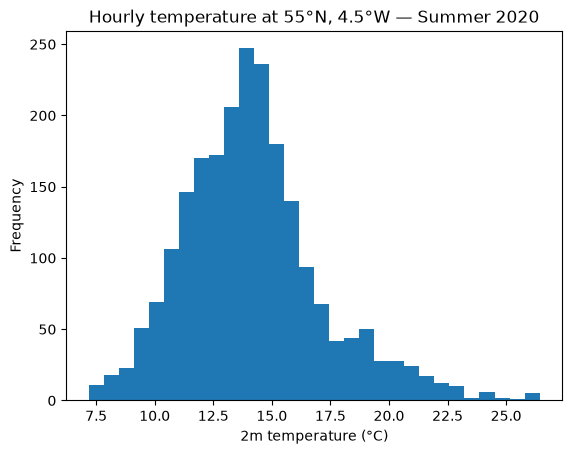

<xarray.DataArray 't2m' (quantile: 5)> Size: 40B
array([ 9.81253052, 12.15548706, 13.90493774, 15.6088562 , 19.92339478])
Coordinates:
  * quantile  (quantile) float64 40B 0.05 0.25 0.5 0.75 0.95
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3185
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [ ]:
import matplotlib.pyplot as plt 
plt.hist(point_c.values, bins=30)
plt.xlabel('2m temperature (°C)')
plt.ylabel('Frequency')
plt.title('Hourly temperature at 55°N, 4.5°W — Summer 2020')
plt.show()

quantiles = point_c.quantile([0.05, 0.25, 0.50, 0.75, 0.95])
quantiles

In [ ]:
print("Mean:  ", point_c.mean().item())
print("Median:", point_c.median().item())



variance = (deviations**2).mean(dim='valid_time')
std_dev = variance**0.5
deviations = point_c - mean_temp

skewness = ((deviations/std_dev)**3).mean(dim='valid_time')
print('Skewness:',  skewness.values)

Mean:   14.166946411132812
Median: 13.904937744140625
Skewness: 0.73660904


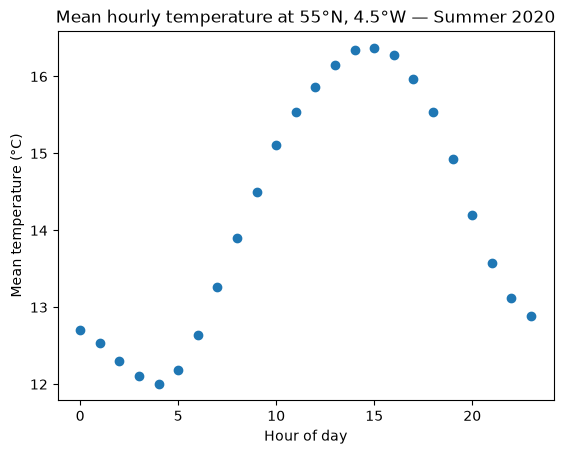

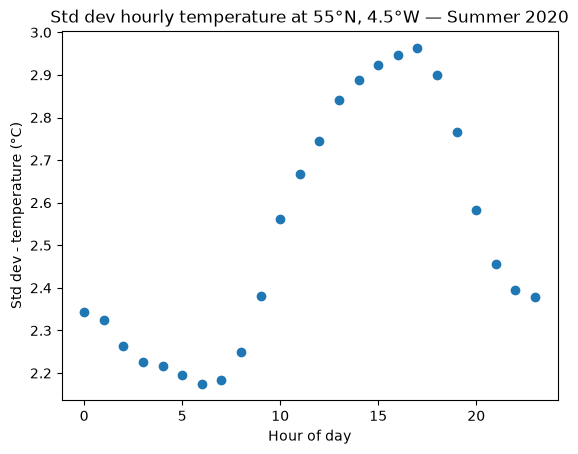

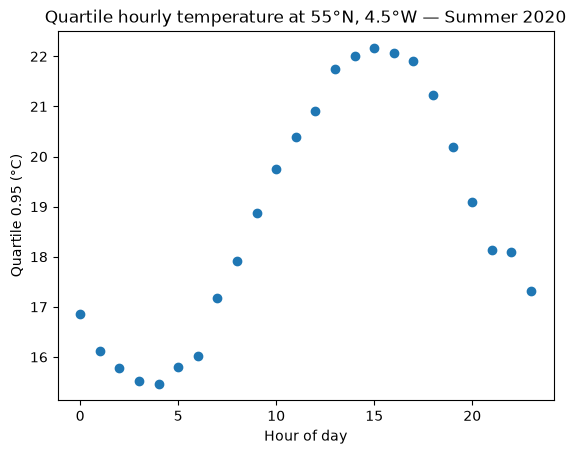

In [ ]:
hourly_mean = point_c.groupby('valid_time.hour').mean()
len(hourly_mean)

plt.scatter(hourly_mean["hour"], hourly_mean)
plt.xlabel("Hour of day")
plt.ylabel("Mean temperature (°C)")
plt.title("Mean hourly temperature at 55°N, 4.5°W — Summer 2020")
plt.show()

#std dev to see the between-day variability across different summer days
hourly_std_dev = point_c.groupby('valid_time.hour').std()
plt.scatter(hourly_std_dev["hour"], hourly_std_dev)
plt.xlabel("Hour of day")
plt.ylabel("Std dev - temperature (°C)")
plt.title("Std dev hourly temperature at 55°N, 4.5°W — Summer 2020")
plt.show()

quartile_095 = point_c.groupby("valid_time.hour").quantile(0.95)
plt.scatter(quartile_095["hour"], quartile_095)
plt.xlabel("Hour of day")
plt.ylabel("Quartile 0.95 (°C)")
plt.title("Quartile hourly temperature at 55°N, 4.5°W — Summer 2020")
plt.show()

In [ ]:
x = point_c.isel(valid_time=slice(0, len(point_c)-1))
y = point_c.isel(valid_time=slice(1, len(point_c)))
print(x.shape)
print(y.shape)

(2207,)
(2207,)


In [ ]:
print(x.valid_time.values[:3])
print(y.valid_time.values[:3])

['2020-06-01T00:00:00.000000000' '2020-06-01T01:00:00.000000000'
 '2020-06-01T02:00:00.000000000']
['2020-06-01T01:00:00.000000000' '2020-06-01T02:00:00.000000000'
 '2020-06-01T03:00:00.000000000']


In [ ]:
x_values = x.values
y_values = y.values
#print(x_values)
mean_x = x_values.mean()
#print(mean_x)
mean_y = y_values.mean()
deviation_x = x_values - mean_x
#print(deviation_x)
deviation_y = y_values - mean_y 
covariance =(deviation_x*deviation_y).mean()
#print(covariance)
std_x = (((x_values - mean_x)**2).mean())**0.5
std_y = (((y_values - mean_y)**2).mean())**0.5

correlation = covariance/(std_x*std_y)
print(correlation)




0.9791632


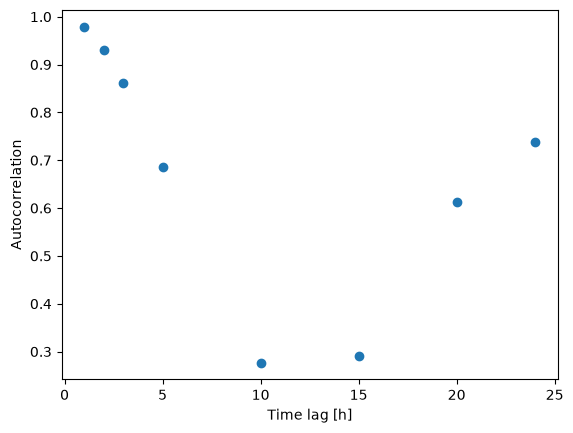

[np.float32(0.9791632), np.float32(0.9306475), np.float32(0.8613543), np.float32(0.7777387), np.float32(0.6849819), np.float32(0.5894754), np.float32(0.49639094), np.float32(0.40996256), np.float32(0.33535472), np.float32(0.2767592), np.float32(0.23771147), np.float32(0.22017136), np.float32(0.22440067), np.float32(0.24888983), np.float32(0.29066765), np.float32(0.34596127), np.float32(0.4105293), np.float32(0.47954684), np.float32(0.54834247), np.float32(0.612553), np.float32(0.6679128), np.float32(0.71014994), np.float32(0.7347674), np.float32(0.73885703), np.float32(0.720927), np.float32(0.68250966), np.float32(0.6270335), np.float32(0.5587782), np.float32(0.48189846), np.float32(0.4009222), np.float32(0.32040974), np.float32(0.24429202), np.float32(0.17676578), np.float32(0.122420594), np.float32(0.08500862), np.float32(0.06667744), np.float32(0.067874745), np.float32(0.08764953), np.float32(0.123856805), np.float32(0.17362249), np.float32(0.2329482), np.float32(0.2969287), np.floa

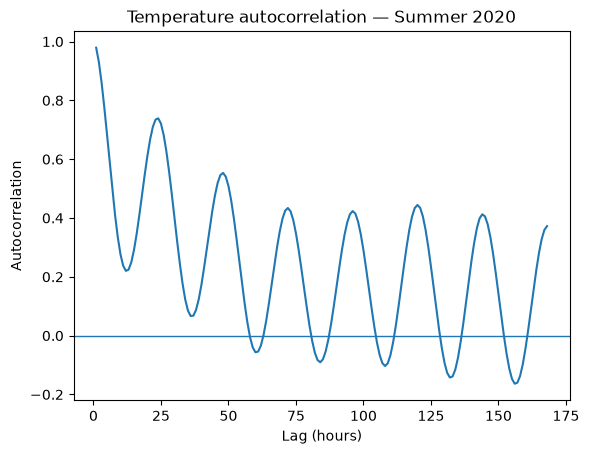

In [ ]:
def autocorrelation(xarray_table, lag):
    n = len(xarray_table)

    x = xarray_table.isel(valid_time=slice(0, n-lag))
    y = xarray_table.isel(valid_time=slice(lag, n))

    x_values = x.values
    y_values = y.values

    mean_x = x_values.mean()
    mean_y = y_values.mean()

    deviation_x = x_values - mean_x
    deviation_y = y_values - mean_y

    covariance = (deviation_x * deviation_y).mean()

    std_x = (deviation_x**2).mean()**0.5
    std_y = (deviation_y**2).mean()**0.5

    correlation = covariance / (std_x * std_y)

    return correlation



lag_points = []
for lag in [1,2,3,5,10,15,20,24]:
    lag_points.append(float(autocorrelation(point_c, lag)))

plt.scatter([1,2,3,5,10,15,20,24], lag_points)
plt.xlabel('Time lag [h]')
plt.ylabel('Autocorrelation')
plt.show()

lags = np.arange(1, 169)
acf = [autocorrelation(point_c, lag) for lag in lags]
print(acf)
plt.plot(lags, acf)

plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Temperature autocorrelation — Summer 2020")
plt.axhline(0, linewidth=1)
plt.show()

In [ ]:
anomaly = point_c.groupby("valid_time.hour") - hourly_mean
len(point_c)

2208

[np.float32(0.9850444), np.float32(0.9577593), np.float32(0.9237463), np.float32(0.88649994), np.float32(0.8472566), np.float32(0.809119), np.float32(0.7737239), np.float32(0.7415711), np.float32(0.7143123), np.float32(0.6923811), np.float32(0.6758807), np.float32(0.66439545), np.float32(0.65707105), np.float32(0.65293086), np.float32(0.65118283), np.float32(0.6515642), np.float32(0.6537154), np.float32(0.65641004), np.float32(0.6584427), np.float32(0.6593664), np.float32(0.6589652), np.float32(0.6569367), np.float32(0.65223455), np.float32(0.64453334), np.float32(0.6333365), np.float32(0.6192048), np.float32(0.6030486), np.float32(0.5856655), np.float32(0.5670211), np.float32(0.5476283), np.float32(0.52837706), np.float32(0.50935566), np.float32(0.49102244), np.float32(0.47435275), np.float32(0.45992774), np.float32(0.4475884), np.float32(0.43675837), np.float32(0.4272831), np.float32(0.4193488), np.float32(0.41374734), np.float32(0.410416), np.float32(0.40797916), np.float32(0.406122

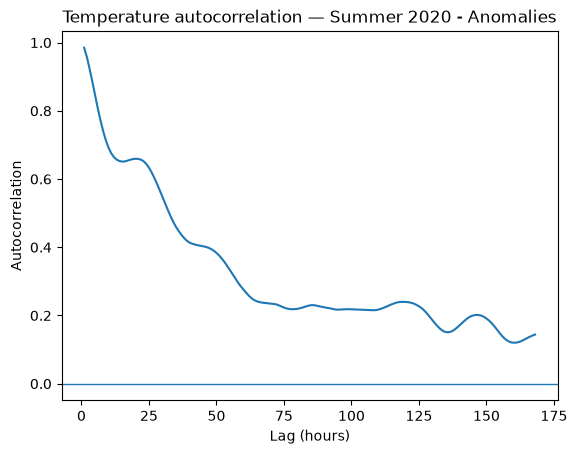

lag: 33 ac: 0.49102244


In [ ]:
acf2 = [autocorrelation(anomaly, lag) for lag in lags]
print(acf2)
plt.plot(lags, acf2)

plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Temperature autocorrelation — Summer 2020 - Anomalies")
plt.axhline(0, linewidth=1)
plt.show()

lags = np.arange(1, 169)

for lag in lags:
    ac = autocorrelation(anomaly, lag)

    if ac < 0.5:
        print("lag:", lag, "ac:", ac)
        break
        
    

In [ ]:
#In this sample, the anomaly autocorrelation first falls below 0.5 at a lag of approximately 33 hours.
#That's descriptive evidence that temperature anomalies retain considerable temporal persistence for more than a day.
acf = [autocorrelation(anomaly, lag) for lag in lags]
acf = np.asarray(acf)

lags[acf < 0.5]



array([ 33,  34,  35,  36,  37,  38,  39,  40,  41,  42,  43,  44,  45,
        46,  47,  48,  49,  50,  51,  52,  53,  54,  55,  56,  57,  58,
        59,  60,  61,  62,  63,  64,  65,  66,  67,  68,  69,  70,  71,
        72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,
        85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
        98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110,
       111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123,
       124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136,
       137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149,
       150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162,
       163, 164, 165, 166, 167, 168])

In [ ]:
threshold = point_c.quantile(0.95)
print(threshold.values)
extreme = point_c > threshold
print(extreme)
print(extreme.dtype)
print(extreme.sum().values)

def sigmoid(z):
    return 1/(1+np.exp(-z))

for z in [-5, -2, 0, 2, 5]:
    print(z, sigmoid(z))
np.exp(-0.7)

19.923394775390626
<xarray.DataArray 't2m' (valid_time: 2208)> Size: 2kB
array([False, False, False, ..., False, False, False], shape=(2208,))
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2020-06-01 ... 2020-08-31T23...
    expver      (valid_time) <U4 35kB ...
    number      int64 8B ...
    latitude    float64 8B 55.0
    longitude   float64 8B -4.5
    quantile    float64 8B 0.95
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3185
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    sta

np.float64(0.4965853037914095)

In [ ]:
loss_A = -np.log(0.9)
loss_B = -np.log(0.1)

print(loss_A)
print(loss_B)
x = np.array([-3, -2, -1, 0, 1, 2, 3])
y = np.array([ 0,  0,  0, 0, 1, 0, 1])

def log_loss(y, p):
    return -(y*np.log(p) + (1-y)*np.log(1-p)).mean()

beta_0 = 0.5
beta_1 = 3
lr = 0.01
for i in range(10001):
    
        
    z = beta_0 + beta_1*x 
    p = sigmoid(z)
    loss = log_loss(y, p)
    if i%100 == 0:
        print('b0=', beta_0, " b1=", beta_1)
        print(f"For step {i}, loss: {loss:.3f}")
    beta_0 -= (p-y).mean()*lr
    beta_1 -= ((p-y)*x).mean()*lr


0.10536051565782628
2.3025850929940455
b0= 0.5  b1= 3
For step 0, loss: 1.084
b0= 0.26620526267653705  b1= 2.732831719755168
For step 100, loss: 0.958
b0= 0.04337584588154927  b1= 2.4706399313702825
For step 200, loss: 0.840
b0= -0.16699884654045657  b1= 2.21613480447658
For step 300, loss: 0.731
b0= -0.36301539662024945  b1= 1.9732308331237534
For step 400, loss: 0.633
b0= -0.5423737989218994  b1= 1.7472407916754493
For step 500, loss: 0.550
b0= -0.7026395847905637  b1= 1.5446797482582733
For step 600, loss: 0.483
b0= -0.8418186770606676  b1= 1.3722336526617898
For step 700, loss: 0.434
b0= -0.9591409372924999  b1= 1.2347174775187437
For step 800, loss: 0.401
b0= -1.0556268714151589  b1= 1.1329590535327327
For step 900, loss: 0.381
b0= -1.1339348151216972  b1= 1.063337962314479
For step 1000, loss: 0.370
b0= -1.1975435533758556  b1= 1.0194220204261493
For step 1100, loss: 0.364
b0= -1.2498696537926652  b1= 0.9942527638129207
For step 1200, loss: 0.361
b0= -1.293761578125992  b1= 0.981

[0 0 0 0 1 0 1]
[0 0 0 0 0 1 1]
x=-3, y=0, p=0.005, prediction=0
x=-2, y=0, p=0.016, prediction=0
x=-1, y=0, p=0.048, prediction=0
x= 0, y=0, p=0.138, prediction=0
x= 1, y=1, p=0.338, prediction=0
x= 2, y=0, p=0.620, prediction=1
x= 3, y=1, p=0.838, prediction=1


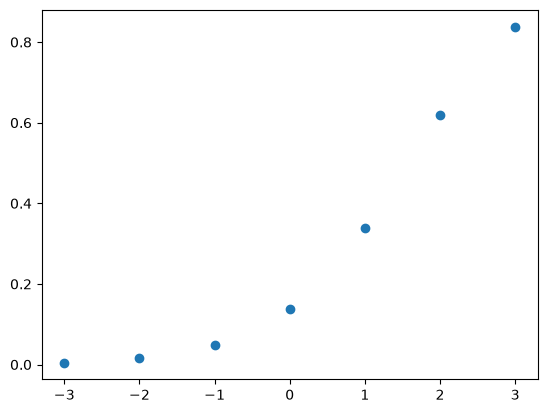

TP:1
TN:4
FP:1
FN:1


In [ ]:
print(y)


z = beta_0 + beta_1*x
p = sigmoid(z)

y_pred = (p >= 0.5).astype(int)
print(y_pred)

for xi, yi, pi, pred in zip(x, y, p, y_pred):
    print(f"x={xi:2d}, y={yi}, p={pi:.3f}, prediction={pred}")

plt.scatter(x,p)

plt.show()

TP = ((y == 1) & (y_pred == 1)).sum()
TN = ((y == 0) & (y_pred == 0)).sum()
FP = ((y == 0) & (y_pred == 1)).sum()
FN = ((y == 1) & (y_pred == 0)).sum()
print(f'TP:{TP}')
print(f'TN:{TN}')
print(f'FP:{FP}')
print(f'FN:{FN}')

In [ ]:
Recall = TP/(TP+FN)
Precision = TP/(TP+FP)
print(Recall)
print(Precision)
point_c

0.5
0.5


<xarray.DataArray 't2m' (valid_time: 2208)> Size: 9kB
array([12.659821, 12.057037, 11.649811, ..., 10.648102, 10.842438,
       10.547516], shape=(2208,), dtype=float32)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2020-06-01 ... 2020-08-31T23...
    expver      (valid_time) <U4 35kB ...
    number      int64 8B ...
    latitude    float64 8B 55.0
    longitude   float64 8B -4.5
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      3185
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [ ]:
n = len(point_c)
print(n)
lag = 24
temperature_yesterday = point_c.isel(valid_time=slice(0, n-2*lag))
temperature_now = point_c.isel(valid_time=slice(lag, n-lag))
temperature_24h_later = point_c.isel(valid_time=slice(2*lag, n))

2208


In [ ]:
print(temperature_now.shape)
print(temperature_24h_later.shape)

print(temperature_now.valid_time.values[0])
print(temperature_24h_later.valid_time.values[0])
y_future = (temperature_24h_later > threshold).astype(int)
print(y_future.values[:20])
print(y_future.sum().values)

(2160,)
(2160,)
2020-06-02T00:00:00.000000000
2020-06-03T00:00:00.000000000
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
103


In [ ]:
temperature_now['valid_time'].values

array(['2020-06-02T00:00:00.000000000', '2020-06-02T01:00:00.000000000',
       '2020-06-02T02:00:00.000000000', ...,
       '2020-08-30T21:00:00.000000000', '2020-08-30T22:00:00.000000000',
       '2020-08-30T23:00:00.000000000'],
      shape=(2160,), dtype='datetime64[ns]')

In [ ]:
df = pd.DataFrame({
    "forecast_time": temperature_now['valid_time'].values,
    "temperature_now": temperature_now.values,
    "extreme_24h": y_future.values
})
df

,forecast_time,temperature_now,extreme_24h
0,2020-06-02 00:00:00,11.641510,0
1,2020-06-02 01:00:00,11.045563,0
2,2020-06-02 02:00:00,10.183502,0
3,2020-06-02 03:00:00,9.710846,0
4,2020-06-02 04:00:00,9.764557,0
...,...,...,...
2155,2020-08-30 19:00:00,12.623932,0
2156,2020-08-30 20:00:00,11.569244,0
2157,2020-08-30 21:00:00,12.065826,0
2158,2020-08-30 22:00:00,11.844147,0


In [ ]:
print(df.head())
print(df.shape)
print(df["extreme_24h"].value_counts())
print(df["extreme_24h"].value_counts(normalize=True))

        forecast_time  temperature_now  extreme_24h
0 2020-06-02 00:00:00        11.641510            0
1 2020-06-02 01:00:00        11.045563            0
2 2020-06-02 02:00:00        10.183502            0
3 2020-06-02 03:00:00         9.710846            0
4 2020-06-02 04:00:00         9.764557            0
(2160, 3)
extreme_24h
0    2057
1     103
Name: count, dtype: int64
extreme_24h
0    0.952315
1    0.047685
Name: proportion, dtype: float64


In [ ]:
temperature_yesterday = point_c.isel(valid_time=slice(0, n-2*lag))

temperature_now = point_c.isel(valid_time=slice(lag, n-lag))

temperature_tomorrow = point_c.isel(valid_time=slice(2*lag, n))

y_future = (temperature_tomorrow > threshold).astype(int)

df = pd.DataFrame({

    "forecast_time": temperature_now['valid_time'].values,
    "temperature_yesterday": temperature_yesterday.values,
    "temperature_now": temperature_now.values,
    "extreme_24h": y_future.values
})
df

,forecast_time,temperature_yesterday,temperature_now,extreme_24h
0,2020-06-02 00:00:00,12.659821,11.641510,0
1,2020-06-02 01:00:00,12.057037,11.045563,0
2,2020-06-02 02:00:00,11.649811,10.183502,0
3,2020-06-02 03:00:00,10.984283,9.710846,0
4,2020-06-02 04:00:00,10.647125,9.764557,0
...,...,...,...,...
2155,2020-08-30 19:00:00,12.389313,12.623932,0
2156,2020-08-30 20:00:00,10.712067,11.569244,0
2157,2020-08-30 21:00:00,10.129059,12.065826,0
2158,2020-08-30 22:00:00,10.454987,11.844147,0


In [ ]:
print(df.shape)

print(temperature_yesterday.valid_time.values[0])
print(temperature_now.valid_time.values[0])
print(temperature_tomorrow.valid_time.values[0])

print(len(temperature_yesterday))
print(len(temperature_now))
print(len(temperature_tomorrow))
print(len(y_future))

(2160, 4)
2020-06-01T00:00:00.000000000
2020-06-02T00:00:00.000000000
2020-06-03T00:00:00.000000000
2160
2160
2160
2160


In [ ]:
df['hour'] = df['forecast_time'].dt.hour

In [ ]:
df['hour_cos'] = np.cos(df['hour']*2*np.pi/24)
df['hour_sin'] = np.sin(df['hour']*2*np.pi/24)
print(df)

,forecast_time,temperature_yesterday,temperature_now,extreme_24h,hour,hour_cos,hour_sin
0,2020-06-02 00:00:00,12.659821,11.641510,0,0,1.000000,0.000000
1,2020-06-02 01:00:00,12.057037,11.045563,0,1,0.965926,0.258819
2,2020-06-02 02:00:00,11.649811,10.183502,0,2,0.866025,0.500000
3,2020-06-02 03:00:00,10.984283,9.710846,0,3,0.707107,0.707107
4,2020-06-02 04:00:00,10.647125,9.764557,0,4,0.500000,0.866025
...,...,...,...,...,...,...,...
2155,2020-08-30 19:00:00,12.389313,12.623932,0,19,0.258819,-0.965926
2156,2020-08-30 20:00:00,10.712067,11.569244,0,20,0.500000,-0.866025
2157,2020-08-30 21:00:00,10.129059,12.065826,0,21,0.707107,-0.707107
2158,2020-08-30 22:00:00,10.454987,11.844147,0,22,0.866025,-0.500000


In [ ]:
print(df)

           forecast_time  temperature_yesterday  temperature_now  extreme_24h  \
0    2020-06-02 00:00:00              12.659821        11.641510            0   
1    2020-06-02 01:00:00              12.057037        11.045563            0   
2    2020-06-02 02:00:00              11.649811        10.183502            0   
3    2020-06-02 03:00:00              10.984283         9.710846            0   
4    2020-06-02 04:00:00              10.647125         9.764557            0   
...                  ...                    ...              ...          ...   
2155 2020-08-30 19:00:00              12.389313        12.623932            0   
2156 2020-08-30 20:00:00              10.712067        11.569244            0   
2157 2020-08-30 21:00:00              10.129059        12.065826            0   
2158 2020-08-30 22:00:00              10.454987        11.844147            0   
2159 2020-08-30 23:00:00               9.469635        11.654205            0   

      hour  hour_cos  hour_

In [ ]:
from pathlib import Path
import cdsapi

DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)

dataset = "reanalysis-era5-single-levels"

client = cdsapi.Client()

for year in range(2010, 2021):

    output_path = DATA_DIR / f"era5_t2m_uk_jja_{year}.nc"

    request = {
        "product_type": ["reanalysis"],
        "variable": ["2m_temperature"],

        "year": [str(year)],

        "month": ["06", "07", "08"],

        "day": [f"{day:02d}" for day in range(1, 32)],

        "time": [f"{hour:02d}:00" for hour in range(24)],

        "data_format": "netcdf",
        "download_format": "unarchived",

        "area": [60, -12, 48, 4]
    }

    print(f"Downloading {year}...")

    client.retrieve(
        dataset,
        request,
        str(output_path)
    )

    print(f"Finished {year}")

2026-09-05 11:13:03,643 INFO Request ID is 29155a2a-6909-4ed4-89b4-54ad4829d467
2026-09-05 11:13:03,726 INFO status has been updated to accepted
2026-09-05 11:13:25,157 INFO status has been updated to running
2026-09-05 11:15:56,755 INFO status has been updated to successful


Finished 2010


2026-09-05 11:16:00,538 INFO Request ID is cb921cad-4801-4744-a06a-39c2f592d3af
2026-09-05 11:16:00,627 INFO status has been updated to accepted
2026-09-05 11:16:23,703 INFO status has been updated to running
2026-09-05 11:20:21,539 INFO status has been updated to successful


Finished 2011


2026-09-05 11:20:26,730 INFO Request ID is 8f1656c5-b5f3-462f-a7b0-0d2b7cd87e52
2026-09-05 11:20:26,811 INFO status has been updated to accepted
2026-09-05 11:20:40,387 INFO status has been updated to running
2026-09-05 11:26:48,097 INFO status has been updated to successful


...

Finished 2018


2026-09-05 11:51:46,469 INFO Request ID is ebcd142a-c8b0-4345-8277-85ee025c0cb9
2026-09-05 11:51:46,657 INFO status has been updated to accepted
2026-09-05 11:52:00,362 INFO status has been updated to running
2026-09-05 11:54:39,239 INFO status has been updated to successful


Finished 2019


2026-09-05 11:54:41,451 INFO Request ID is 4b915223-af7d-47a2-8184-1880f84c1841
2026-09-05 11:54:41,556 INFO status has been updated to accepted
2026-09-05 11:55:03,252 INFO status has been updated to successful
                                                                                         

Finished 2020


In [6]:
import numpy as np
import pandas as pd
import xarray as xr
import cdsapi
from pathlib import Path

DATA_DIR = Path("../data")

files = sorted(DATA_DIR.glob("era5_t2m_uk_jja_20*.nc"))

print("Number of files:", len(files))

for file in files:
    print(file.name)

files = [
    DATA_DIR / f"era5_t2m_uk_jja_{year}.nc"
    for year in range(2010, 2021)
]

datasets = []

for file in files:
    ds_year = xr.open_dataset(file)
    datasets.append(ds_year)

print(len(datasets))

Number of files: 11
era5_t2m_uk_jja_2010.nc
era5_t2m_uk_jja_2011.nc
era5_t2m_uk_jja_2012.nc
era5_t2m_uk_jja_2013.nc
era5_t2m_uk_jja_2014.nc
era5_t2m_uk_jja_2015.nc
era5_t2m_uk_jja_2016.nc
era5_t2m_uk_jja_2017.nc
era5_t2m_uk_jja_2018.nc
era5_t2m_uk_jja_2019.nc
era5_t2m_uk_jja_2020.nc
11


In [7]:
ds_all = xr.concat(
    datasets,
    dim="valid_time"
)

In [8]:
print(ds_all.sizes)

print(ds_all.valid_time.values[0])
print(ds_all.valid_time.values[-1])

print(ds_all.sizes["valid_time"])

Frozen({'valid_time': 24288, 'latitude': 49, 'longitude': 65})
2010-06-01T00:00:00.000000000
2020-08-31T23:00:00.000000000
24288


In [9]:
times = ds_all["valid_time"].values
time_diff = np.diff(times)

print(time_diff[:10] / np.timedelta64(1, "h"))

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [10]:
one_hour = np.timedelta64(1, "h")

gap_indices = np.where(time_diff != one_hour)[0]

print("Number of gaps:", len(gap_indices))
print("Gap indices:", gap_indices)

for i in gap_indices:
    print(
        times[i],
        "→",
        times[i + 1],
        "| gap:",
        time_diff[i] / np.timedelta64(1, "D"),
        "days"
    )

training_data = []

for ds_year in datasets:

    point = ds_year["t2m"].isel(
        latitude=20,
        longitude=30
    )

    point_c_year = point - 273.15

    year = point_c_year.valid_time.dt.year.values[0]

    if year <= 2018:
        training_data.append(point_c_year)
        
training_temperature = xr.concat(
    training_data,
    dim="valid_time"
)


print(len(training_temperature))
threshold = training_temperature.quantile(0.95)
print(threshold)

Number of gaps: 10
Gap indices: [ 2207  4415  6623  8831 11039 13247 15455 17663 19871 22079]
2010-08-31T23:00:00.000000000 → 2011-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2011-08-31T23:00:00.000000000 → 2012-06-01T00:00:00.000000000 | gap: 274.0416666666667 days
2012-08-31T23:00:00.000000000 → 2013-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2013-08-31T23:00:00.000000000 → 2014-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2014-08-31T23:00:00.000000000 → 2015-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2015-08-31T23:00:00.000000000 → 2016-06-01T00:00:00.000000000 | gap: 274.0416666666667 days
2016-08-31T23:00:00.000000000 → 2017-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2017-08-31T23:00:00.000000000 → 2018-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2018-08-31T23:00:00.000000000 → 2019-06-01T00:00:00.000000000 | gap: 273.0416666666667 days
2019-08-31T23:00:00.000000000 → 2020-06-01T00:00:00.000000000 | gap: 274.04166

In [11]:
all_rows = []

for ds_year in datasets:

    point = ds_year["t2m"].isel(
        latitude=20,
        longitude=30
    )

    point_c_year = point - 273.15

    n = len(point_c_year)
    lag = 24

    temperature_yesterday = point_c_year.isel(
        valid_time=slice(0, n - 2*lag)
    )

    temperature_now = point_c_year.isel(
        valid_time=slice(lag, n - lag)
    )

    temperature_tomorrow = point_c_year.isel(
        valid_time=slice(2*lag, n)
    )

    y_future = (temperature_tomorrow > threshold).astype(int)

    df_year = pd.DataFrame({
        "forecast_time": temperature_now["valid_time"].values,
        "temperature_yesterday": temperature_yesterday.values,
        "temperature_now": temperature_now.values,
        "extreme_24h": y_future.values
    })

    all_rows.append(df_year)

df = pd.concat(
    all_rows,
    ignore_index=True
)
df

,forecast_time,temperature_yesterday,temperature_now,extreme_24h
0,2010-06-02 00:00:00,11.905670,9.494049,0
1,2010-06-02 01:00:00,11.411285,9.013336,0
2,2010-06-02 02:00:00,11.134186,9.360016,0
3,2010-06-02 03:00:00,11.095367,9.678253,0
4,2010-06-02 04:00:00,11.093292,9.574127,0
...,...,...,...,...
23755,2020-08-30 19:00:00,12.389313,12.623932,0
23756,2020-08-30 20:00:00,10.712067,11.569244,0
23757,2020-08-30 21:00:00,10.129059,12.065826,0
23758,2020-08-30 22:00:00,10.454987,11.844147,0


In [12]:
df["year"] = df["forecast_time"].dt.year
yearly_summary = df.groupby("year")["extreme_24h"].agg(
    ["count", "sum", "mean"]
)

print(yearly_summary)

      count  sum      mean
year                      
2010   2160   46  0.021296
2011   2160   38  0.017593
2012   2160   45  0.020833
2013   2160  202  0.093519
2014   2160  156  0.072222
2015   2160   49  0.022685
2016   2160  109  0.050463
2017   2160   79  0.036574
2018   2160  252  0.116667
2019   2160  160  0.074074
2020   2160  176  0.081481


In [13]:
train_mask = df["year"] <= 2018

print(
    df.loc[train_mask, "extreme_24h"].mean()
)

df["hour"] = df["forecast_time"].dt.hour

df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

0.050205761316872426


In [14]:
train_df = df[df["year"] <= 2018].copy()
val_df   = df[df["year"] == 2019].copy()
test_df  = df[df["year"] == 2020].copy()

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(19440, 8)
(2160, 8)
(2160, 8)


In [15]:
features_to_standardize = [
    "temperature_yesterday",
    "temperature_now"
] 
for feature in features_to_standardize:

    mean = train_df[feature].mean()
    std = train_df[feature].std()

    train_df[feature + "_z"] = (train_df[feature] - mean) / std

    val_df[feature + "_z"] = (val_df[feature] - mean) / std

    test_df[feature + "_z"] = (test_df[feature] - mean) / std

In [16]:
for feature in features_to_standardize:

    z_feature = feature + "_z"

    print(z_feature)

    print("train mean:", train_df[z_feature].mean())
    print("train std: ", train_df[z_feature].std())

    print("val mean:  ", val_df[z_feature].mean())
    print("test mean: ", test_df[z_feature].mean())

    print()

temperature_yesterday_z
train mean: -3.9245856e-07
train std:  1.0
val mean:   0.17280307
test mean:  0.051290993

temperature_now_z
train mean: 8.791072e-08
train std:  0.99999994
val mean:   0.1854993
test mean:  0.032072414



In [17]:
model_features = [
    "temperature_yesterday_z",
    "temperature_now_z",
    "hour_sin",
    "hour_cos"
]

X_train = train_df[model_features].values
y_train = train_df["extreme_24h"].values

X_val = val_df[model_features].values
y_val = val_df["extreme_24h"].values

X_test = test_df[model_features].values
y_test = test_df["extreme_24h"].values

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(19440, 4) (19440,)
(2160, 4) (2160,)
(2160, 4) (2160,)


In [18]:
def log_loss(y, p):
    eps = 1e-15
    p = np.clip(p, eps, 1 - eps)

    return -np.mean(
        y * np.log(p)
        + (1 - y) * np.log(1 - p)
    )

In [35]:
learning_rate = 0.1

def sigmoid(z):
    return 1/(1+np.exp(-z))
beta_0 = 0 
beta = np.zeros(X_train.shape[1]) #nx1 where n=number of features
beta0_values = []
beta_values = []
loss_values = []
epoch_list = []
for epoch in range(10000):

    z = beta_0 + X_train @ beta
    p = sigmoid(z)

    loss = log_loss(y_train, p)
    gradient_beta_0 = (p-y_train).mean()
    gradient_beta = X_train.T@(p-y_train)/len(y_train)

    beta_0 -= gradient_beta_0*learning_rate
    beta -= gradient_beta*learning_rate
    beta0_values.append(beta_0)
    beta_values.append(beta.copy())
    loss_values.append(loss)
    epoch_list.append(epoch)
    if epoch%1000 == 0:
        print('========================')
        print('Epoch:', epoch)
        print('Loss:' , loss)
        print('grad_b0:',gradient_beta_0)
        print('grad_b:' , gradient_beta)
    if epoch == 9999:
        print('b0=',beta_0)
        print('b=',beta)



Epoch: 0
Loss: 0.6931471805599454
grad_b0: 0.44979423868312757
grad_b: [-0.07533758 -0.09206522  0.02184099  0.02821744]
Epoch: 1000
Loss: 0.11799848081308367
grad_b0: 0.007603680764772902
grad_b: [ 0.00092764 -0.00492497  0.00105156  0.0012196 ]
Epoch: 2000
Loss: 0.1141012466181159
grad_b0: 0.0030736143307877745
grad_b: [ 0.00085434 -0.00208964  0.00081259  0.00107458]
Epoch: 3000
Loss: 0.11314780588416429
grad_b0: 0.0016683461135071787
grad_b: [ 0.00053447 -0.0010561   0.00060228  0.00082925]
Epoch: 4000
Loss: 0.11281129515930187
grad_b0: 0.001023029092491933
grad_b: [ 0.00032157 -0.00057988  0.0004417   0.00061601]
Epoch: 5000
Loss: 0.11267168688909782
grad_b0: 0.000668376651673728
grad_b: [ 0.00019503 -0.00033671  0.00032303  0.00045155]
Epoch: 6000
Loss: 0.11260833068424095
grad_b0: 0.00045303900202396837
grad_b: [ 0.00012086 -0.00020431  0.00023603  0.00032942]
Epoch: 7000
Loss: 0.11257797595542075
grad_b0: 0.00031421025238895537
grad_b: [ 7.68400787e-05 -1.28621781e-04  1.723709

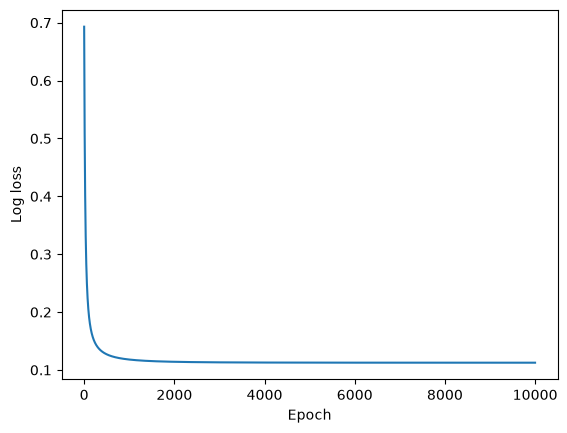

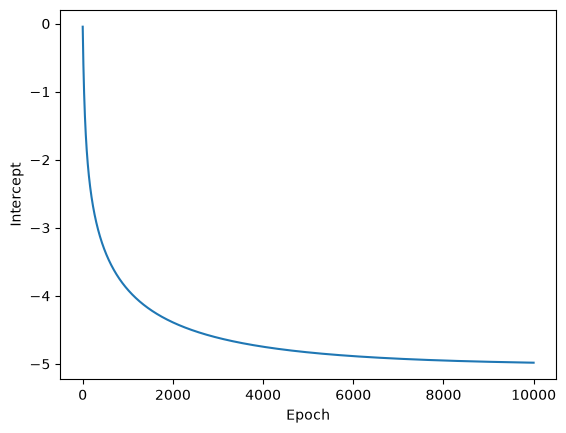

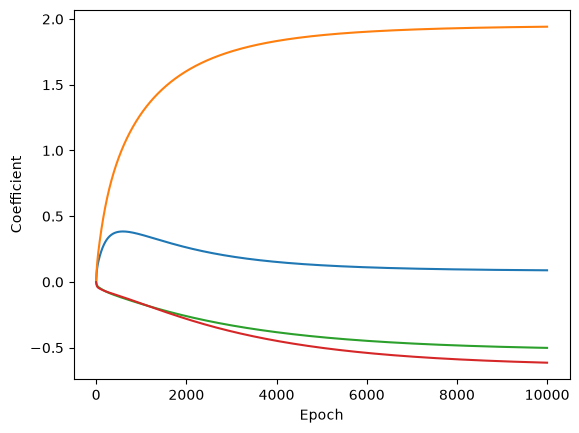

In [21]:

import matplotlib.pyplot as plt 
plt.plot(epoch_list, loss_values)
plt.xlabel("Epoch")
plt.ylabel("Log loss")
plt.show()

plt.plot(epoch_list, beta0_values)
plt.xlabel("Epoch")
plt.ylabel("Intercept")
plt.show()

plt.plot(epoch_list, beta_values)
plt.xlabel("Epoch")
plt.ylabel("Coefficient")
plt.show()


In [22]:
z_val = beta_0 + X_val @ beta
p_val = sigmoid(z_val)

print("Train loss:", log_loss(y_train, sigmoid(beta_0 + X_train @ beta)))
print("Validation loss:", log_loss(y_val, p_val))
print("Validation prevalence:", y_val.mean())
print("Mean predicted probability:", p_val.mean())

Train loss: 0.1125513735383877
Validation loss: 0.1747531948474118
Validation prevalence: 0.07407407407407407
Mean predicted probability: 0.06639677357984056


In [23]:
train_prevalence = y_train.mean()
print(train_prevalence)
p_baseline = np.full(len(y_val),train_prevalence) #a simple model that always predicts the same prob for every observation

baseline_loss = log_loss(y_val, p_baseline)

print("Baseline validation loss:", baseline_loss)
print("Logistic validation loss:", log_loss(y_val, p_val))

0.050205761316872426
Baseline validation loss: 0.2692962481802879
Logistic validation loss: 0.1747531948474118


In [24]:
df_val_check = pd.DataFrame({'target y val': y_val, 'p_val':p_val})
df_val_check

,target y val,p_val
0,0,0.001919
1,0,0.001868
2,0,0.002042
3,0,0.001884
4,0,0.001384
...,...,...
2155,0,0.029514
2156,0,0.024748
2157,0,0.019366
2158,0,0.016414


In [25]:
p_extreme = p_val[y_val == 1]
p_non_extreme = p_val[y_val == 0]

print("Actual extremes:")
print("count:", len(p_extreme))
print("mean predicted p:", p_extreme.mean())
print("median predicted p:", np.median(p_extreme))

print("\nActual non-extremes:")
print("count:", len(p_non_extreme))
print("mean predicted p:", p_non_extreme.mean())
print("median predicted p:", np.median(p_non_extreme))

Actual extremes:
count: 160
mean predicted p: 0.32941750727363533
median predicted p: 0.2712301365375149

Actual non-extremes:
count: 2000
mean predicted p: 0.045355114884336974
median predicted p: 0.007617411631183605


In [ ]:
p_extreme.shape

(160,)

In [ ]:
p_non_extreme.shape

(2000,)

In [26]:
comparisons = p_extreme[:, None] > p_non_extreme
print(comparisons.shape)
print(comparisons.mean())

(160, 2000)
0.91540625


In [27]:
greater = p_extreme[:, None] > p_non_extreme
equal = p_extreme[:, None] == p_non_extreme

auc_manual = greater.mean() + 0.5 * equal.mean()
auc_manual

np.float64(0.91540625)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
               mean_predicted_probability  observed_extreme_frequency  count
bin                                                                         
(-0.001, 0.1]                    0.016175                    0.021966   1821
(0.1, 0.2]                       0.142379                    0.219697    132
(0.2, 0.3]                       0.244212                    0.265625     64
(0.3, 0.4]                       0.338394                    0.350000     40
(0.4, 0.5]                       0.441455                    0.586207     29
(0.5, 0.6]                       0.548969                    0.708333     24
(0.6, 0.7]                       0.654972                    0.533333     15
(0.7, 0.8]                       0.745254                    0.750000      8
(0.8, 0.9]                       0.854138                    0.250000     12
(0.9, 1.0]                       0.932591                    0.600000     15


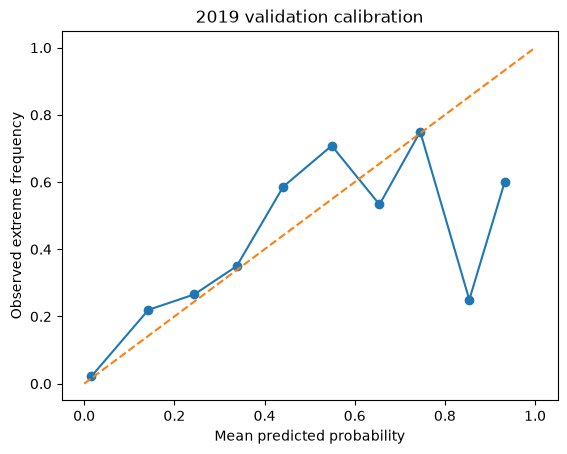

In [28]:
bins = np.linspace(0, 1, 11)
print(bins)

calibration_df = pd.DataFrame({
    "p": p_val,
    "y": y_val
})

calibration_df["bin"] = pd.cut(
    calibration_df["p"],
    bins=bins,
    include_lowest=True
)

calibration = calibration_df.groupby(
    "bin",
    observed=True
).agg(
    mean_predicted_probability=("p", "mean"),
    observed_extreme_frequency=("y", "mean"),
    count=("y", "size")
)

print(calibration)
plt.plot(
    calibration["mean_predicted_probability"],
    calibration["observed_extreme_frequency"],
    marker="o"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed extreme frequency")
plt.title("2019 validation calibration")
plt.show()

In [29]:
calibration_df["quantile_bin"] = pd.qcut(
    calibration_df["p"],
    q=10,
    duplicates="drop"
)
calibration_q = calibration_df.groupby(
    "quantile_bin",
    observed=True
).agg(
    mean_predicted_probability=("p", "mean"),
    observed_extreme_frequency=("y", "mean"),
    count=("y", "size")
)

print(calibration_q)

                        mean_predicted_probability  \
quantile_bin                                         
(-0.0009859, 0.000393]                    0.000170   
(0.000393, 0.00136]                       0.000821   
(0.00136, 0.00269]                        0.001982   
(0.00269, 0.00515]                        0.003855   
(0.00515, 0.00974]                        0.007196   
(0.00974, 0.0188]                         0.013579   
(0.0188, 0.0334]                          0.025323   
(0.0334, 0.0669]                          0.048390   
(0.0669, 0.19]                            0.113963   
(0.19, 0.966]                             0.448690   

                        observed_extreme_frequency  count  
quantile_bin                                               
(-0.0009859, 0.000393]                    0.000000    216  
(0.000393, 0.00136]                       0.000000    216  
(0.00136, 0.00269]                        0.000000    216  
(0.00269, 0.00515]                        0.000000 

In [33]:
threshold = 0.2
y_pred = (p_val >= threshold).astype(int)

TP = ((y_val == 1) & (y_pred == 1)).sum()
TN = ((y_val == 0) & (y_pred == 0)).sum()
FP = ((y_val == 0) & (y_pred == 1)).sum()
FN = ((y_val == 1) & (y_pred == 0)).sum()
#Recall
TPR = TP/(TP+FN)
# incorrect flagged as extreme over the total non-extremes
FPR = FP/(FP+TN)
print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)
print("TPR:", TPR) # true positive ratio, 26.8% are flagged as extremes out of 160 actual extremes
print("FPR:", FPR) # false positive ratio, 1.55% are falsely flagged as extremes out of 2000 non extremes

TP: 91
TN: 1884
FP: 116
FN: 69
TPR: 0.56875
FPR: 0.058


In [31]:
thresholds = np.linspace(1, 0, 101)

tpr_values = []
fpr_values = []

for threshold in thresholds:

    y_pred = (p_val >= threshold).astype(int)

    TP = ((y_val == 1) & (y_pred == 1)).sum()
    TN = ((y_val == 0) & (y_pred == 0)).sum()
    FP = ((y_val == 0) & (y_pred == 1)).sum()
    FN = ((y_val == 1) & (y_pred == 0)).sum()

    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)

    tpr_values.append(TPR)
    fpr_values.append(FPR)

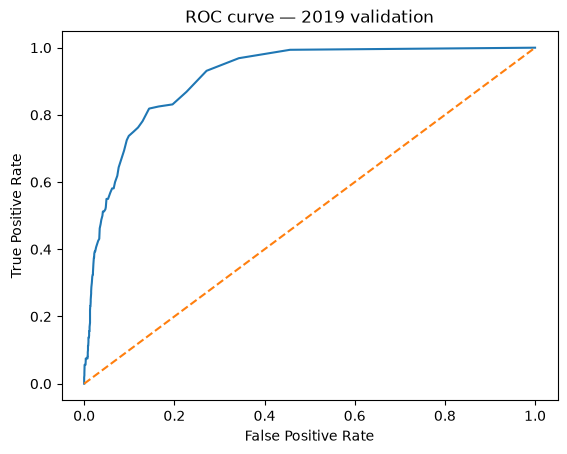

0.91313125


In [34]:
plt.plot(fpr_values, tpr_values)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve — 2019 validation")
plt.show()

auc_roc = np.trapezoid(tpr_values, fpr_values)

print(auc_roc)

In [ ]:
thresholds_exact = np.sort(np.unique(p_val))[::-1]
print(len(thresholds_exact))
print(thresholds_exact[:10])

thresholds_exact = np.r_[np.inf, np.sort(np.unique(p_val))[::-1]]

tpr_exact = []
fpr_exact = []

for threshold in thresholds_exact:

    y_pred = (p_val >= threshold).astype(int)

    TP = ((y_val == 1) & (y_pred == 1)).sum()
    TN = ((y_val == 0) & (y_pred == 0)).sum()
    FP = ((y_val == 0) & (y_pred == 1)).sum()
    FN = ((y_val == 1) & (y_pred == 0)).sum()

    TPR = TP / (TP + FN)
    FPR = FP / (FP + TN)

    tpr_exact.append(TPR)
    fpr_exact.append(FPR)

    auc_exact = np.trapezoid(tpr_exact, fpr_exact)

print("ROC AUC:", auc_exact)
print("Pairwise AUC:", auc_manual)

In [36]:
beta_sin = beta[2]
beta_cos = beta[3]

amplitude = np.sqrt(beta_sin**2 + beta_cos**2)

print(amplitude)

0.7928737713992045


In [38]:
hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

time_effect = (
    beta_sin * hour_sin
    + beta_cos * hour_cos
)

for h, effect in zip(hours, time_effect):
    print(h, effect)

max_hour = hours[np.argmax(time_effect)]
min_hour = hours[np.argmin(time_effect)]

print("Maximum time effect:", max_hour)
print("Minimum time effect:", min_hour)

0 -0.6141325678904644
1 -0.723001099779921
2 -0.782598301535186
3 -0.788862722345671
4 -0.7413674522855862
5 -0.6433492155198816
6 -0.5014877929013447
7 -0.3254508059443436
8 -0.12723488439512193
9 0.07965188426003933
10 0.28111050863384135
11 0.4634119164013273
12 0.6141325678904643
13 0.723001099779921
14 0.782598301535186
15 0.788862722345671
16 0.7413674522855864
17 0.6433492155198814
18 0.5014877929013448
19 0.32545080594434384
20 0.1272348843951217
21 -0.07965188426003916
22 -0.28111050863384096
23 -0.4634119164013269
Maximum time effect: 15
Minimum time effect: 3


0 0.0036985121853018053
1 0.0033182703735780764
2 0.0031268886669436045
3 0.0031074224251762383
4 0.0032580788535765196
5 0.0035923999165433833
6 0.004137676959479001
7 0.004930179437119494
8 0.006004511287363577
9 0.007374430591521224
10 0.0090054756846584
11 0.010786927148614529
12 0.012519687582376154
13 0.013939576410334338
14 0.014782936430549341
15 0.01487445183996553
16 0.014194293525201428
17 0.012886083739374912
18 0.011200879193656773
19 0.009409924140088394
20 0.007731032128245175
21 0.006295288469148678
22 0.005152552289409209
23 0.004297570295272326


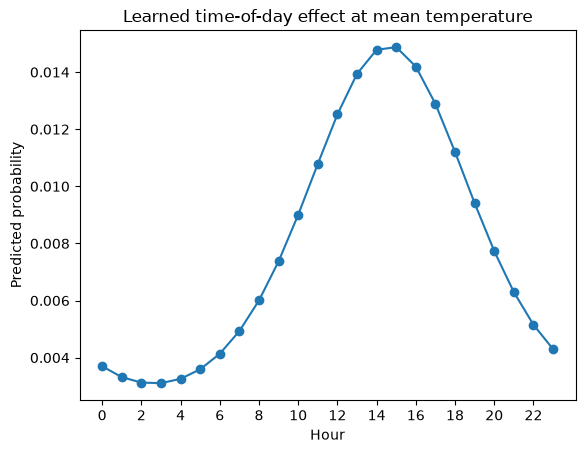

In [41]:
z_hour = beta_0 + time_effect
p_hour = sigmoid(z_hour)

for h, p in zip(hours, p_hour):
    print(h, p)

plt.plot(hours, p_hour, marker="o")
plt.xlabel("Hour")
plt.ylabel("Predicted probability")
plt.title("Learned time-of-day effect at mean temperature")
plt.xticks(range(0, 24, 2))
plt.show()

In [43]:
mean_now = train_df["temperature_now"].mean()
std_now = train_df["temperature_now"].std()

print("Training mean:", mean_now)
print("Training std:", std_now)
print("z = -2:", mean_now - 2*std_now)
print("z = -1:", mean_now - std_now)
print("z =  0:", mean_now)
print("z = +1:", mean_now + std_now)
print("z = +2:", mean_now + 2*std_now)
print("z = +3:", mean_now + 3*std_now)

Training mean: 14.076964
Training std: 2.735129
z = -2: 8.606707
z = -1: 11.341835
z =  0: 14.076964
z = +1: 16.812094
z = +2: 19.547222
z = +3: 22.282352


In [ ]:
train_prevalence = y_train.mean()

probabilities = np.full(
        n_samples,
        train_prevalence,
        dtype=float,
    )

In [1]:
import sys
import ssl
import requests
import certifi

print("Python:")
print(sys.executable)

print("\nRequests CA:")
print(requests.certs.where())

print("\nCertifi CA:")
print(certifi.where())

print("\nSSL paths:")
print(ssl.get_default_verify_paths())

Python:
c:\ProgramData\anaconda3\envs\climate-ml\python.exe

Requests CA:
c:\ProgramData\anaconda3\envs\climate-ml\Lib\site-packages\certifi\cacert.pem

Certifi CA:
c:\ProgramData\anaconda3\envs\climate-ml\Lib\site-packages\certifi\cacert.pem

SSL paths:
DefaultVerifyPaths(cafile='c:\\ProgramData\\anaconda3\\envs\\climate-ml\\Library\\ssl\\cacert.pem', capath='c:\\ProgramData\\anaconda3\\envs\\climate-ml\\Library\\ssl\\certs', openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='C:\\Program Files\\Common Files\\ssl\\cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='C:\\Program Files\\Common Files\\ssl\\certs')


In [2]:
import requests

try:
    r = requests.get(
        "https://www.google.com",
        timeout=10,
    )
    print("Status:", r.status_code)
except Exception as e:
    print(type(e).__name__)
    print(e)

Status: 200


In [3]:
import cdsapi

client = cdsapi.Client()
print("CDS client created successfully")

CDS client created successfully


In [4]:
from pathlib import Path
import cdsapi

DATA_DIR = Path("../data")
DATA_DIR.mkdir(exist_ok=True)

DATASET = "reanalysis-era5-single-levels"


def download_era5_year(year):
    output_path = DATA_DIR / f"era5_atmos_uk_jja_{year}.nc"

    if output_path.exists():
        print(f"Already exists: {output_path}")
        return

    request = {
        "product_type": ["reanalysis"],
        "variable": [
            "2m_temperature",
            "2m_dewpoint_temperature",
            "mean_sea_level_pressure",
            "10m_u_component_of_wind",
            "10m_v_component_of_wind",
        ],
        "year": [str(year)],
        "month": ["06", "07", "08"],
        "day": [
            f"{day:02d}"
            for day in range(1, 32)
        ],
        "time": [
            f"{hour:02d}:00"
            for hour in range(24)
        ],
        "area": [
            60,
            -12,
            48,
            4,
        ],
        "data_format": "netcdf",
        "download_format": "unarchived",
    }

    print(f"Downloading ERA5 for {year}...")

    client = cdsapi.Client()

    client.retrieve(
        DATASET,
        request,
        str(output_path),
    )

    print(f"Saved: {output_path}")

In [ ]:
download_era5_year(2010)

2026-10-02 00:19:19,039 INFO Request ID is 30451e06-95d4-4de0-bf27-199082de749e
2026-10-02 00:19:19,695 INFO status has been updated to accepted
2026-10-02 00:19:35,197 INFO status has been updated to running
2026-10-02 00:29:45,803 INFO status has been updated to successful
                                                                                         

Saved: ..\data\era5_atmos_uk_jja_2010.nc


: 

In [1]:
import os

for name in [
    "SSL_CERT_FILE",
    "SSL_CERT_DIR",
    "REQUESTS_CA_BUNDLE",
    "CURL_CA_BUNDLE",
    "HTTP_PROXY",
    "HTTPS_PROXY",
]:
    print(f"{name} = {os.environ.get(name)}")

SSL_CERT_FILE = c:\ProgramData\anaconda3\envs\climate-ml\Library\ssl\cacert.pem
SSL_CERT_DIR = c:\ProgramData\anaconda3\envs\climate-ml\Library\ssl\certs
REQUESTS_CA_BUNDLE = None
CURL_CA_BUNDLE = None
HTTP_PROXY = None
HTTPS_PROXY = None


In [5]:
import os
print(os.getcwd())

%cd ..
print(os.getcwd())

c:\WIP\my_work\climate-extremes\notebooks
c:\WIP\my_work\climate-extremes
c:\WIP\my_work\climate-extremes


In [6]:
%run scripts/download_era5.py

Already exists: data\era5_atmos_uk_jja_2010.nc


In [7]:
import xarray as xr

file_path = "data/era5_atmos_uk_jja_2010.nc"

ds = xr.open_dataset(file_path)

print(ds)
print("Variables:")
print(ds.data_vars)

print("\nSizes:")
print(ds.sizes)

for variable in ds.data_vars:
    print(
        variable,
        ds[variable].shape,
        ds[variable].attrs.get("units")
    )

<xarray.Dataset> Size: 141MB
Dimensions:     (valid_time: 2208, latitude: 49, longitude: 65)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 18kB 2010-06-01 ... 2010-08-31T23...
    expver      (valid_time) <U4 35kB ...
  * latitude    (latitude) float64 392B 60.0 59.75 59.5 ... 48.5 48.25 48.0
  * longitude   (longitude) float64 520B -12.0 -11.75 -11.5 ... 3.5 3.75 4.0
    number      int64 8B ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 28MB ...
    d2m         (valid_time, latitude, longitude) float32 28MB ...
    msl         (valid_time, latitude, longitude) float32 28MB ...
    u10         (valid_time, latitude, longitude) float32 28MB ...
    v10         (valid_time, latitude, longitude) float32 28MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre 